# Project 19 | Credit Card Fraud Detection
**Ensemble learning • Executed simulated benchmark**

The task is to flag rare fraudulent transactions for review. The bundled dataset is simulated, not real bank data. The optional ULB benchmark is documented in README. Do not use this prototype for actual payment decisions.

## 1. Setup and inspect the data
Run from the extracted project folder. In Colab, upload and extract the ZIP, change to the project folder and install `requirements.txt` before running these cells.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from generate_data import ROOT, FEATURES
from train import load_data, run, DEFAULT_DATA
from predict import load_model, score_transactions
df, removed = load_data(DEFAULT_DATA)
print(f"Rows: {len(df):,}; features: {len(FEATURES)}; duplicates/conflicts removed: {removed}")
display(df.head())
print(df.Class.value_counts())
print("Fraud rate:", df.Class.mean())

Rows: 50,000; features: 30; duplicates/conflicts removed: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,153706,-0.09426,-1.75773,-1.46705,2.12925,-1.28742,-1.09679,1.83691,2.90507,-1.17157,-0.36825,0.34156,1.72870,-0.98686,-0.24528,0.77734,0.43477,-0.37616,-0.13382,-1.37490,-0.23817,-0.26639,0.23217,-0.55533,0.47154,1.01272,0.15543,0.35176,0.05316,13.94,0
1,109728,0.00008,-0.72156,0.31649,-0.09729,2.09317,1.57335,0.38585,-0.76306,-1.11241,1.19114,0.26275,0.48014,-1.74459,0.92744,0.45442,-1.11043,-0.47152,0.26372,0.05247,-0.29217,-0.10349,-0.25198,0.15256,1.47149,-2.56666,-0.23685,0.17651,0.29599,39.13,0
2,82334,-0.37191,-1.75672,0.32800,1.72735,-1.53386,0.86383,-0.32853,-0.06132,-1.05290,-0.33446,1.30004,0.58266,1.73231,1.17741,0.43909,1.74393,0.43899,0.82799,-0.29657,0.06655,-0.69742,0.98958,-1.17830,0.78235,-0.19065,1.17125,0.75087,1.82065,17.75,0
3,57626,0.73077,-1.57204,-0.06695,-1.17201,-0.51828,1.51123,0.63753,-0.69893,-1.01372,0.03278,-1.21656,-0.67114,0.31201,1.15531,0.60876,-2.29129,0.30437,0.07203,0.41389,1.61621,-2.06324,-0.59110,0.59091,-1.58159,1.47595,0.36836,0.84658,-0.57094,23.38,0
4,82639,0.81376,1.06847,0.23288,0.23440,0.27034,-0.86335,-0.14753,-0.15252,0.38339,0.99982,-1.05854,-0.12501,1.48146,-0.74359,-0.82225,0.20231,0.84439,0.01143,1.32896,0.85679,0.84182,0.55412,2.32765,-0.20516,-2.00352,1.60425,-0.45770,0.10788,29.10,0


Class
0    49750
1      250
Name: count, dtype: int64
Fraud rate: 0.005


## 2. Preprocessing and model development
Validate numeric finite features and target, remove duplicate/conflicting records, and stratify 60/20/20. Use a majority baseline plus weighted Decision Tree, Random Forest, XGBoost and LightGBM. No resampling of validation or test data. The training function saves plots and metrics. Model choice is based on validation average precision, with thresholds tuned on validation F1.

            model  threshold  accuracy  precision  recall     f1  average_precision  roc_auc   tn  fp  fn  tp
Majority baseline     0.5000    0.9950     0.0000    0.00 0.0000             0.0050   0.5000 9950   0  50   0
    Decision Tree     0.9861    0.9951     0.5079    0.64 0.5664             0.4858   0.8191 9919  31  18  32
    Random Forest     0.2367    0.9977     0.8462    0.66 0.7416             0.7502   0.9435 9944   6  17  33
          XGBoost     0.8373    0.9981     0.9189    0.68 0.7816             0.7514   0.9557 9947   3  16  34
         LightGBM     0.9610    0.9927     0.3175    0.40 0.3540             0.1349   0.6922 9907  43  30  20
Selected: XGBoost
{'train': {'rows': 30000, 'fraud': 150}, 'validation': {'rows': 10000, 'fraud': 50}, 'test': {'rows': 10000, 'fraud': 50}}


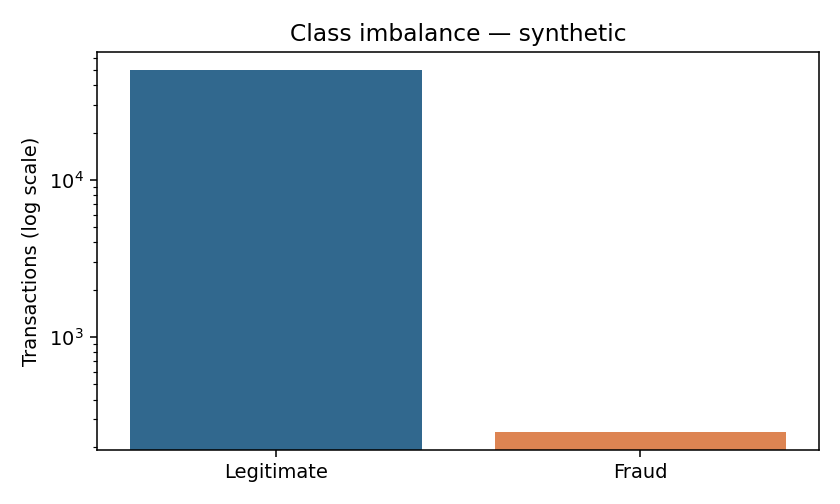

In [2]:
out = ROOT / "notebook_run"
summary = run(DEFAULT_DATA, out, mode="synthetic")
print(summary["splits"])
display(Image(filename=str(out / "class_distribution.png")))

## 3. Validation and held-out evaluation
The model and thresholds are frozen before test evaluation. Average precision is emphasized for severe imbalance. Accuracy alone hides minority-class failures.

,model,threshold,fit_seconds,accuracy,precision,recall,f1,average_precision,roc_auc,tn,fp,fn,tp
0,Majority baseline,0.5000,0.0040,0.9950,0.0000,0.00,0.0000,0.0050,0.5000,9950,0,50,0
1,Decision Tree,0.9861,0.8512,0.9950,0.5000,0.60,0.5455,0.3898,0.7658,9920,30,20,30
2,Random Forest,0.2367,4.2299,0.9975,0.8205,0.64,0.7191,0.6442,0.9581,9943,7,18,32
3,XGBoost,0.8373,0.2928,0.9975,0.8378,0.62,0.7126,0.6646,0.9467,9944,6,19,31
4,LightGBM,0.9610,0.2838,0.9940,0.4074,0.44,0.4231,0.1768,0.6968,9918,32,28,22


,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,tn,fp,fn,tp
0,Majority baseline,0.5000,0.9950,0.0000,0.00,0.0000,0.0050,0.5000,9950,0,50,0
1,Decision Tree,0.9861,0.9951,0.5079,0.64,0.5664,0.4858,0.8191,9919,31,18,32
2,Random Forest,0.2367,0.9977,0.8462,0.66,0.7416,0.7502,0.9435,9944,6,17,33
3,XGBoost,0.8373,0.9981,0.9189,0.68,0.7816,0.7514,0.9557,9947,3,16,34
4,LightGBM,0.9610,0.9927,0.3175,0.40,0.3540,0.1349,0.6922,9907,43,30,20


Selected: XGBoost


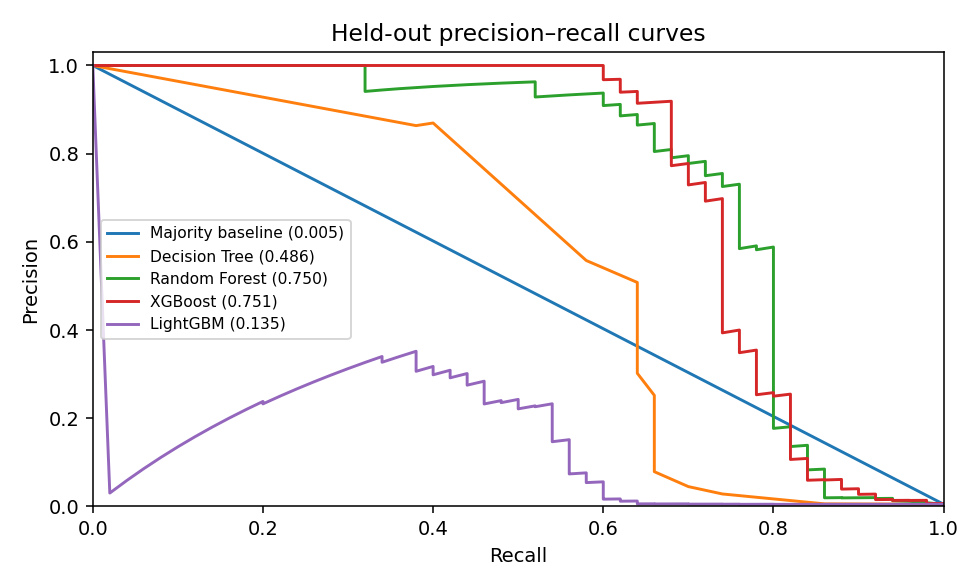

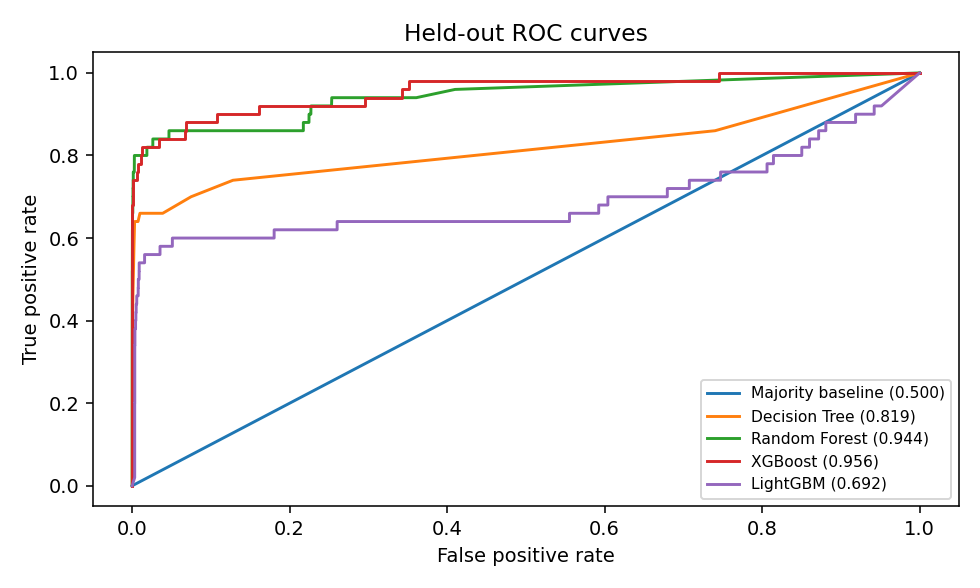

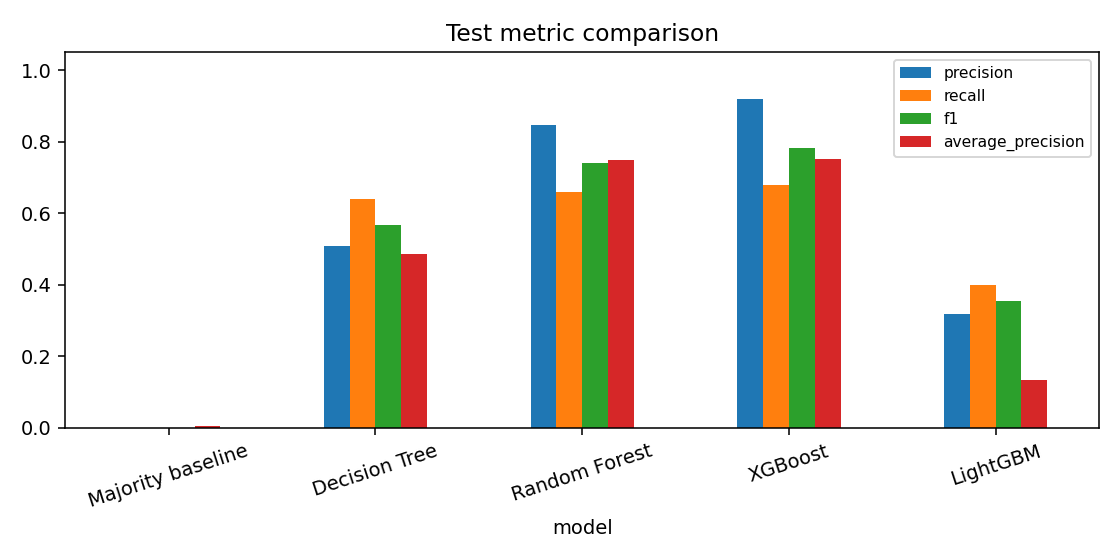

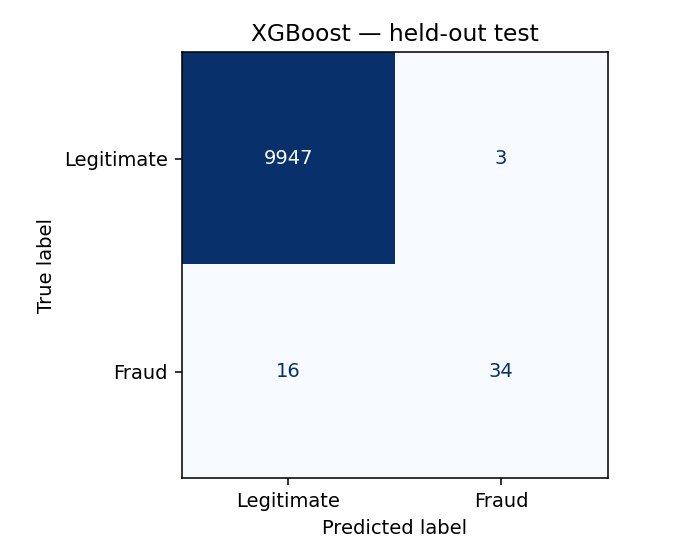

In [3]:
display(pd.read_csv(out / "validation_metrics.csv").round(4))
display(pd.read_csv(out / "test_metrics.csv").round(4))
print("Selected:", summary["selected_model"])
for name in ["precision_recall.png", "roc.png", "model_comparison.png", "confusion_matrix.png"]:
    display(Image(filename=str(out / name)))

## 4. Interpret errors
False positives cause unnecessary review; false negatives are missed frauds. Feature importance measures model split utility, not causality. Simulated data deliberately contains overlapping patterns.

{'threshold': 0.837266206741333, 'accuracy': 0.9981, 'precision': 0.918918918918919, 'recall': 0.68, 'f1': 0.7816091954022989, 'average_precision': 0.7514442377583345, 'roc_auc': 0.9557085427135678, 'tn': 9947.0, 'fp': 3.0, 'fn': 16.0, 'tp': 34.0}


,actual,predicted,score
0,1,0,0.004056
1,1,0,0.012423
2,1,0,0.310852
3,1,0,0.672399
4,1,0,0.665005
5,0,1,0.936111
6,1,0,0.199406
7,1,0,0.207070
8,1,0,0.040438
9,1,0,0.100385


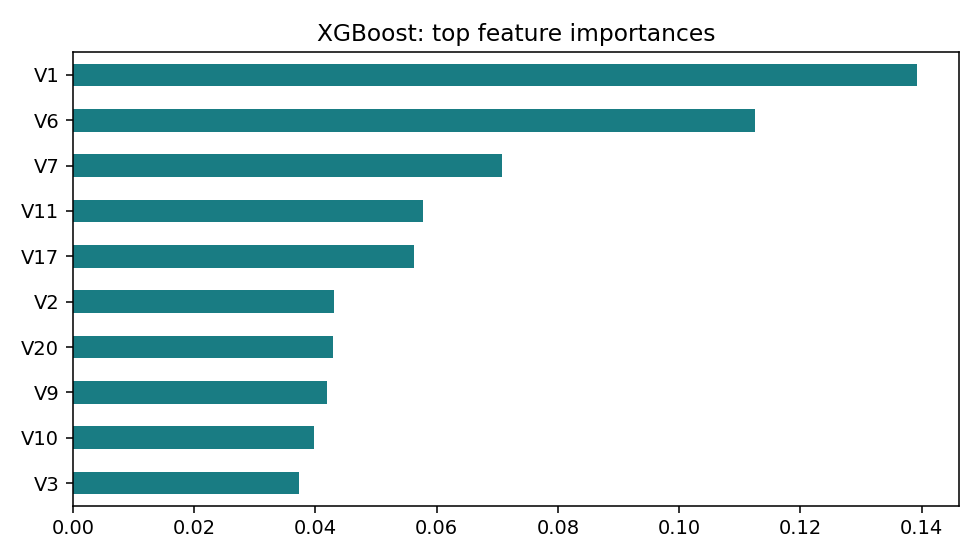

In [4]:
print(summary["test_metrics"])
errors = pd.read_csv(out / "test_errors.csv")
display(errors[["actual", "predicted", "score"]].head(10))
if (out / "feature_importance.png").exists():
    display(Image(filename=str(out / "feature_importance.png")))

## 5. Working prototype
Use held-out examples or edit the feature values in a copy. A flag means human review; the score is not calibrated. For an interactive browser form, run `python app.py` in a terminal.

In [5]:
bundle = load_model(out / "model.joblib")
examples = pd.read_csv(out / "example_transactions.csv")
display(pd.concat([examples[["Class", "Amount"]], score_transactions(examples, bundle)], axis=1))
# Editable example: provide all 30 numeric fields.
example = examples.iloc[[0]][FEATURES].copy()
example.loc[:, "Amount"] = 100.0
display(score_transactions(example, bundle))

,Class,Amount,risk_score,flag_for_review
0,0,193.51,0.005663,0
1,0,16.80,0.003081,0
2,0,45.22,0.002697,0
3,1,52.30,0.004056,0
4,1,206.35,0.012423,0
5,1,12.20,0.982912,1


,risk_score,flag_for_review
0,0.006125,0


## 6. Conclusion and limitations
Compare AP and confusion matrices rather than accuracy alone. The bundled run uses a simulated 0.5% fraud dataset; patterns may not reflect real fraud. The actual benchmark could not be downloaded in the build environment. For real data, follow README and report those results separately. Real deployment requires temporal validation, monitoring, calibration and privacy safeguards.